In [1]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.0 MB/s eta 0:00:0000:01


2026-03-17 12:34:02.136334: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773750842.327870      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773750842.401069      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773750842.884796      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773750842.884829      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773750842.884832      55 computation_placer.cc:177] computation placer alr

Loaded ECG samples: 21837
Total exceptions: 0


I0000 00:00:1773751481.899436      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1773751481.902654      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/65


I0000 00:00:1773751498.858193     139 service.cc:152] XLA service 0x7bd420003b00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773751498.858254     139 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1773751498.858261     139 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1773751501.655149     139 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1773751522.705130     139 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


433/433 ━━━━━━━━━━━━━━━━━━━━ 103s 149ms/step - accuracy: 0.6101 - loss: 1.7011 - val_accuracy: 0.7689 - val_loss: 1.2666
Epoch 2/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 73s 169ms/step - accuracy: 0.7693 - loss: 1.2014 - val_accuracy: 0.7821 - val_loss: 1.0078
Epoch 3/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 73s 169ms/step - accuracy: 0.7806 - loss: 0.9826 - val_accuracy: 0.7961 - val_loss: 0.8875
Epoch 4/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 74s 171ms/step - accuracy: 0.8001 - loss: 0.8324 - val_accuracy: 0.7887 - val_loss: 0.7863
Epoch 5/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 74s 170ms/step - accuracy: 0.7961 - loss: 0.7542 - val_accuracy: 0.7541 - val_loss: 0.7924
Epoch 6/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 74s 171ms/step - accuracy: 0.8073 - loss: 0.6776 - val_accuracy: 0.7878 - val_loss: 0.6670
Epoch 7/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 74s 170ms/step - accuracy: 0.8087 - loss: 0.6257 - val_accuracy: 0.7434 - val_loss: 0.6994
Epoch 8/65
433/433 ━━━━━━━━━━━━━━━━━━━━ 73s 170ms/step - accuracy: 0.8190 - loss: 0.5864 - va

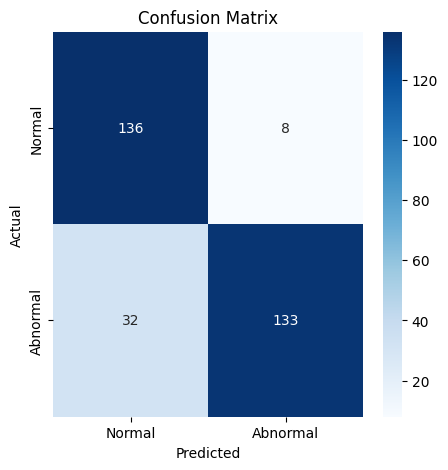

Model: "Hybrid_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ECG_Input           │ (None, 500, 12)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ PCG_Input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_mamba_model     │ (None, 256)       │  2,643,200 │ ECG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pcg_transformer     │ (None, 256)       │  2,433,280 │ PCG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 256)       │     65,792 │ ecg_mamba_model[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 256)       │     65,792 │ pcg_transformer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 512)       │          0 │ dense_26[0][0],   │
│ (Concatenate)       │                   │            │ dense_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 256)       │    131,328 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 256)       │          0 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 256)       │          0 │ dense_28[0][0],   │
│                     │                   │            │ dense_26[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 256)       │          0 │ subtract[0][0],   │
│ (Multiply)          │                   │            │ dense_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 256)       │          0 │ multiply[0][0],   │
│                     │                   │            │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_mamba_b… │ (None, 256)       │    329,216 │ add_2[0][0]       │
│ (MultimodalMambaBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_mamba_b… │ (None, 256)       │    329,216 │ multimodal_mamba… │
│ (MultimodalMambaBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_35 (Dense)    │ (None, 2)         │        514 │ multimodal_mamba… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,995,016 (68.65 MB)

 Trainable params: 5,998,338 (22.88 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,996,678 (45.76 MB)

In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from imblearn.over_sampling import SMOTE
from scipy.io import wavfile
from scipy.signal import stft
import wfdb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd  # Added for PTB-XL CSV reading
import ast  # For parsing string lists in PTB-XL CSV
from tensorflow.keras import callbacks  # Added for early stopping if not already imported

# --- ECG Mamba Model Implementation (from ECGMamba paper) ---
# This is a minimal, self-contained Mamba block for 1D ECG data, inspired by the paper.
# If you have the official Mamba library, you can use it directly. Otherwise, this is a simplified version.

class SimpleMambaBlock(layers.Layer):
    def __init__(self, d_model, ssm_dim, dropout=0.5, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.ssm_dim = ssm_dim
        self.dropout = dropout
        self.dense1 = layers.Dense(ssm_dim, activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.dense2 = layers.Dense(d_model, kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.gate_dense = layers.Dense(d_model, activation='sigmoid', kernel_regularizer=tf.keras.regularizers.l2(1e-4))  # Gating mechanism      
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        # SSM-like block: project, nonlinearity, project back, residual
        h = self.dense1(x)
        h = self.drop(h, training=training)
        h = self.dense2(h)
        h = self.drop(h, training=training)
        gate = self.gate_dense(x)  # Learn to select/weight features
        h = gate * h + (1 - gate) * x  # Selective residual connection
        return self.norm(h)

# ECG Mamba Model

def ecg_mamba_model(input_shape, d_model=128, ssm_dim=256, num_blocks=4, dropout=0.5):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(d_model, kernel_size=3, padding='same', activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inputs)
    for _ in range(num_blocks):
        x = SimpleMambaBlock(d_model, ssm_dim, dropout)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="ecg_mamba_model")

# Multimodal Mamba Fusion Block
class MultimodalMambaBlock(layers.Layer):
    def __init__(self, d_model, ssm_dim, dropout=0.5, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.ssm_dim = ssm_dim
        self.dropout = dropout
        self.dense1 = layers.Dense(ssm_dim, activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.dense2 = layers.Dense(d_model, kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.gate_dense = layers.Dense(d_model, activation='sigmoid', kernel_regularizer=tf.keras.regularizers.l2(1e-4))  # Gating for fusion
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        h = self.dense1(x)
        h = self.drop(h, training=training)
        h = self.dense2(h)
        h = self.drop(h, training=training)
        gate = self.gate_dense(x)
        h = gate * h + (1 - gate) * x
        return self.norm(h)

# Multimodal Mamba Fusion Model (now with selective fusion)
def multimodal_mamba_fusion(ecg_output, pcg_output, d_model=256, ssm_dim=512, num_blocks=2, dropout=0.5):
    # Paper-inspired selective fusion: learn a gate for each modality, then combine
    # 1. Project both modalities to same dim
    ecg_proj = layers.Dense(d_model, activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(ecg_output)
    pcg_proj = layers.Dense(d_model, activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(pcg_output)
    # 2. Learn a fusion gate (0-1) for each modality
    fusion_input = layers.Concatenate()([ecg_proj, pcg_proj])
    fusion_gate = layers.Dense(d_model, activation='sigmoid', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(fusion_input)
    # 3. Weighted sum (selective fusion)
    fused = fusion_gate * ecg_proj + (1 - fusion_gate) * pcg_proj
    x = fused
    for _ in range(num_blocks):
        x = MultimodalMambaBlock(d_model, ssm_dim, dropout)(x)
    return x

# Constants
IMG_HEIGHT = 128
IMG_WIDTH = 128
PATCH_SIZE = 16
EMBED_DIM = 256
NUM_HEADS = 8
FF_DIM = 512
DROPOUT_RATE = 0.5
NUM_CLASSES = 2
INPUT_ECG_SHAPE = (500, 12)  # 12 leads instead of 1
INPUT_PCG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 1)
BATCH_SIZE = 32
EPOCHS = 65
LEARNING_RATE = 3e-4

# Helper function to compute PCG spectrogram
def compute_spectrogram(filepath):
    sample_rate, signal = wavfile.read(filepath)
    frequencies, times, spectrogram = stft(signal, fs=sample_rate, nperseg=256)
    spectrogram = np.log(np.abs(spectrogram) + 1e-10)
    spectrogram = np.resize(spectrogram, (IMG_HEIGHT, IMG_WIDTH))
    return spectrogram

# Load PCG dataset with augmentation for abnormal cases
def load_pcg_dataset(normal_dir, abnormal_dir):
    data, labels = [], []
    for label, directory in enumerate([normal_dir, abnormal_dir]):
        for filename in os.listdir(directory):
            if filename.endswith(".wav"):
                filepath = os.path.join(directory, filename)
                spectrogram = compute_spectrogram(filepath)
                data.append(spectrogram)
                labels.append(label)
                # Augment abnormal data by flipping
                if label == 1:
                    flipped_spectrogram = np.flip(spectrogram, axis=1)
                    data.append(flipped_spectrogram)
                    labels.append(label)
    return np.array(data), np.array(labels)

# --- PTB-XL ECG Data Loader (all leads) ---
def load_ptbxl_ecg_data(csv_path, records_path, num_samples=500):
    df = pd.read_csv(csv_path)
    available_records = []
    for root, dirs, files in os.walk(records_path):
        for file in files:
            if file.endswith('.hea'):
                base_id = file.split('_')[0]
                base_id = str(base_id).zfill(5)
                available_records.append(file.replace('.hea', ''))
    available_records = set(available_records)
    df = df[df['ecg_id'].astype(str).str.zfill(5).apply(lambda rid: any(rid in rec for rec in available_records))]
    X, Y = [], []
    exception_count = 0
    for idx, row in df.iterrows():
        rec_id = str(row['ecg_id']).zfill(5)
        rec_folder = rec_id[:2] + "000"
        rec_candidates = [rec for rec in available_records if rec.startswith(rec_id)]
        if not rec_candidates:
            if exception_count < 5:
                print(f"No matching record file for ecg_id {rec_id}")
            exception_count += 1
            continue
        rec_file = rec_candidates[0]
        rec_path = os.path.join(records_path, rec_folder, rec_file)
        try:
            signal, fields = wfdb.rdsamp(rec_path)
            # Use all 12 leads, shape: (time, 12)
            if signal.shape[0] < num_samples or signal.shape[1] < 12:
                continue
            # Take a random segment of num_samples
            start = np.random.randint(0, signal.shape[0] - num_samples + 1)
            segment = signal[start:start+num_samples, :12]  # shape (num_samples, 12)
            X.append(segment)
            scp_codes = ast.literal_eval(row['scp_codes']) if isinstance(row['scp_codes'], str) else row['scp_codes']
            label = 0 if 'NORM' in scp_codes else 1
            Y.append(label)
        except Exception as e:
            if exception_count < 5:
                print(f"Exception for record {rec_id}: {e}")
            exception_count += 1
            continue
    print(f"Loaded ECG samples: {len(X)}")
    print(f"Total exceptions: {exception_count}")
    return np.array(X), np.array(Y)

# --- Data Augmentation Utilities ---
import random

def add_ecg_noise(ecg, noise_level=0.05):
    noise = np.random.normal(0, noise_level, ecg.shape)
    return ecg + noise

def scale_ecg(ecg, scale_range=(0.9, 1.1)):
    scale = np.random.uniform(*scale_range)
    return ecg * scale

def time_mask_ecg(ecg, max_mask=20):
    ecg = ecg.copy()
    mask_len = np.random.randint(1, max_mask)
    start = np.random.randint(0, ecg.shape[0] - mask_len)
    ecg[start:start+mask_len, :] = 0
    return ecg

# --- Aggressive ECG Augmentation: time warping, random erasing, cutmix ---
def augment_ecg(ecg):
    # Add noise
    if np.random.rand() < 0.5:
        ecg = add_ecg_noise(ecg)
    # Scale
    if np.random.rand() < 0.5:
        ecg = scale_ecg(ecg)
    # Time masking
    if np.random.rand() < 0.3:
        ecg = time_mask_ecg(ecg)
    # Time warping (random stretch/compress)
    if np.random.rand() < 0.3:
        orig_len = ecg.shape[0]
        warp_factor = np.random.uniform(0.8, 1.2)
        new_len = int(orig_len * warp_factor)
        ecg = np.array([np.interp(np.linspace(0, orig_len-1, new_len), np.arange(orig_len), ecg[:,i]) for i in range(ecg.shape[1])]).T
        if new_len > orig_len:
            ecg = ecg[:orig_len, :]
        else:
            pad = np.zeros((orig_len-new_len, ecg.shape[1]))
            ecg = np.concatenate([ecg, pad], axis=0)
    # Random erasing (zero out a random segment)
    if np.random.rand() < 0.2:
        seg_len = np.random.randint(10, 40)
        start = np.random.randint(0, ecg.shape[0] - seg_len)
        ecg[start:start+seg_len, :] = 0
    return ecg

def freq_mask_spectrogram(spec, max_mask=20):
    spec = spec.copy()
    num_freqs = spec.shape[0]
    mask_len = np.random.randint(1, max_mask)
    start = np.random.randint(0, num_freqs - mask_len)
    spec[start:start+mask_len, :] = 0
    return spec

def time_mask_spectrogram(spec, max_mask=20):
    spec = spec.copy()
    num_times = spec.shape[1]
    mask_len = np.random.randint(1, max_mask)
    start = np.random.randint(0, num_times - mask_len)
    spec[:, start:start+mask_len] = 0
    return spec

# --- Aggressive Spectrogram Augmentation: time/freq warping, random erasing, cutmix ---
def augment_spectrogram(spec):
    # Frequency masking
    if np.random.rand() < 0.5:
        spec = freq_mask_spectrogram(spec)
    # Time masking
    if np.random.rand() < 0.5:
        spec = time_mask_spectrogram(spec)
    # Time warping (stretch/compress along time axis)
    if np.random.rand() < 0.3:
        orig_len = spec.shape[1]
        warp_factor = np.random.uniform(0.8, 1.2)
        new_len = int(orig_len * warp_factor)
        spec = np.array([np.interp(np.linspace(0, orig_len-1, new_len), np.arange(orig_len), spec[i,:]) for i in range(spec.shape[0])])
        if new_len > orig_len:
            spec = spec[:, :orig_len]
        else:
            pad = np.zeros((spec.shape[0], orig_len-new_len))
            spec = np.concatenate([spec, pad], axis=1)
    # Random erasing (zero out a random patch)
    if np.random.rand() < 0.2:
        freq_len = np.random.randint(5, 20)
        time_len = np.random.randint(5, 20)
        f0 = np.random.randint(0, spec.shape[0] - freq_len)
        t0 = np.random.randint(0, spec.shape[1] - time_len)
        spec[f0:f0+freq_len, t0:t0+time_len] = 0
    return spec

# --- CutMix for ECG and PCG ---
def cutmix_ecg(ecg1, ecg2):
    # Randomly select a segment and replace with another sample
    seg_len = np.random.randint(20, 80)
    start = np.random.randint(0, ecg1.shape[0] - seg_len)
    ecg = ecg1.copy()
    ecg[start:start+seg_len, :] = ecg2[start:start+seg_len, :]
    return ecg

def cutmix_spectrogram(spec1, spec2):
    # Randomly select a patch and replace with another sample
    freq_len = np.random.randint(10, 40)
    time_len = np.random.randint(10, 40)
    f0 = np.random.randint(0, spec1.shape[0] - freq_len)
    t0 = np.random.randint(0, spec1.shape[1] - time_len)
    spec = spec1.copy()
    spec[f0:f0+freq_len, t0:t0+time_len] = spec2[f0:f0+freq_len, t0:t0+time_len]
    return spec

# Mixup for ECG and PCG
def mixup(x1, y1, x2, y2, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    x = lam * x1 + (1 - lam) * x2
    y = lam * y1 + (1 - lam) * y2
    return x, y

# Data paths
pcg_normal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor/combined_heart_sound_data(physionet +circor)/Normal"
pcg_abnormal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor/combined_heart_sound_data(physionet +circor)/Abnormal"
# Use PTB-XL dataset path for ECG
ptbxl_data_path = "/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"
ptbxl_csv_path = os.path.join(ptbxl_data_path, "ptbxl_database.csv")
ptbxl_records_path = os.path.join(ptbxl_data_path, "records100")


early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

# Load and preprocess PCG data
pcg_data, pcg_labels = load_pcg_dataset(pcg_normal_dir, pcg_abnormal_dir)
pcg_data = pcg_data / np.max(pcg_data)
pcg_data = np.expand_dims(pcg_data, -1)
pcg_labels = tf.keras.utils.to_categorical(pcg_labels, NUM_CLASSES)

# Load and preprocess ECG data using PTB-XL (all leads)
X_clean, Y_clean = load_ptbxl_ecg_data(ptbxl_csv_path, ptbxl_records_path, num_samples=500)
scaler = StandardScaler()
X_clean = np.array([scaler.fit_transform(x) for x in X_clean])  # shape (n, 500, 12)
Y_clean = np.array(Y_clean)

# Apply SMOTE to balance ECG dataset
X_clean_reshaped = X_clean.reshape((X_clean.shape[0], -1))  # shape (n, 2400)
smote = SMOTE(random_state=42)
X_clean_bal, Y_clean_bal = smote.fit_resample(X_clean_reshaped, Y_clean)
Y_clean_bal = tf.keras.utils.to_categorical(Y_clean_bal, NUM_CLASSES)
X_clean_bal = X_clean_bal.reshape((-1, 500, 12))

# --- Apply Data Augmentation to Datasets ---
# Augment PCG data (spectrograms) with more aggressive augmentations
aug_pcg_data = []
aug_pcg_labels = []
for i in range(len(pcg_data)):
    spec = pcg_data[i][..., 0]  # Remove channel for augmentation
    label = pcg_labels[i]
    aug_pcg_data.append(pcg_data[i])  # original
    aug_pcg_labels.append(label)
    # Standard augmentation
    if np.random.rand() < 0.5:
        aug_spec = augment_spectrogram(spec)
        aug_pcg_data.append(np.expand_dims(aug_spec, -1))
        aug_pcg_labels.append(label)
    # CutMix augmentation
    if np.random.rand() < 0.2:
        j = np.random.randint(0, len(pcg_data))
        spec2 = pcg_data[j][..., 0]
        cutmix_spec = cutmix_spectrogram(spec, spec2)
        aug_pcg_data.append(np.expand_dims(cutmix_spec, -1))
        aug_pcg_labels.append(label)

pcg_data = np.array(aug_pcg_data)
pcg_labels = np.array(aug_pcg_labels)

# Augment ECG data (all leads) with more aggressive augmentations
aug_ecg_data = []
aug_ecg_labels = []
for i in range(len(X_clean_bal)):
    ecg = X_clean_bal[i]
    label = Y_clean_bal[i]
    aug_ecg_data.append(ecg)  # original
    aug_ecg_labels.append(label)
    # Standard augmentation
    if np.random.rand() < 0.5:
        aug_ecg = augment_ecg(ecg)
        aug_ecg_data.append(aug_ecg)
        aug_ecg_labels.append(label)
    # CutMix augmentation
    if np.random.rand() < 0.2:
        j = np.random.randint(0, len(X_clean_bal))
        ecg2 = X_clean_bal[j]
        cutmix_ecg_aug = cutmix_ecg(ecg, ecg2)
        aug_ecg_data.append(cutmix_ecg_aug)
        aug_ecg_labels.append(label)

X_clean_bal = np.array(aug_ecg_data)
Y_clean_bal = np.array(aug_ecg_labels)

# Balance datasets
min_samples = min(len(X_clean_bal), len(pcg_data))
X_clean_bal, Y_clean_bal = shuffle(X_clean_bal[:min_samples], Y_clean_bal[:min_samples], random_state=42)
pcg_data, pcg_labels = shuffle(pcg_data[:min_samples], pcg_labels[:min_samples], random_state=42)

# Train-test split
x_train_pcg, x_test_pcg, y_train_pcg, y_test_pcg = train_test_split(pcg_data, pcg_labels, test_size=0.1, random_state=42)
x_val_pcg, x_test_pcg, y_val_pcg, y_test_pcg = train_test_split(x_test_pcg, y_test_pcg, test_size=0.2, random_state=42)

x_train_ecg, x_test_ecg, y_train_ecg, y_test_ecg = train_test_split(X_clean_bal, Y_clean_bal, test_size=0.1, random_state=42)
x_val_ecg, x_test_ecg, y_val_ecg, y_test_ecg = train_test_split(x_test_ecg, y_test_ecg, test_size=0.2, random_state=42)

# Patch Embedding Layer for PCG
def patch_embedding(input_shape, patch_size, embed_dim):
    inputs = layers.Input(shape=input_shape)
    patches = layers.Conv2D(embed_dim, (patch_size, patch_size), strides=(patch_size, patch_size), kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inputs)
    flat_patches = layers.Reshape((-1, embed_dim))(patches)
    return models.Model(inputs, flat_patches, name="patch_embedding")

# Transformer Block
def transformer_block(embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=(None, embed_dim))
    attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)(inputs, inputs)
    attention_output = layers.Dropout(dropout_rate)(attention_output)
    attention_output = layers.LayerNormalization(epsilon=1e-6)(inputs + attention_output)

    ffn_output = layers.Dense(ff_dim, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(attention_output)
    ffn_output = layers.Dense(embed_dim, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(ffn_output)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    outputs = layers.LayerNormalization(epsilon=1e-6)(attention_output + ffn_output)

    return models.Model(inputs, outputs, name="transformer_block")

# PCG Transformer Model
def pcg_transformer(input_shape, patch_size, embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=input_shape)
    x = patch_embedding(input_shape, patch_size, embed_dim)(inputs)
    x = transformer_block(embed_dim, num_heads, ff_dim, dropout_rate)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="pcg_transformer")

# Final Hybrid Model
def hybrid_transformer_model():
    ecg_input = layers.Input(shape=INPUT_ECG_SHAPE, name="ECG_Input")
    pcg_input = layers.Input(shape=INPUT_PCG_SHAPE, name="PCG_Input")

    # Use ECG Mamba model instead of transformer
    ecg_model = ecg_mamba_model(INPUT_ECG_SHAPE, d_model=256, ssm_dim=512, num_blocks=8, dropout=0.5)
    pcg_model = pcg_transformer(INPUT_PCG_SHAPE, PATCH_SIZE, EMBED_DIM, NUM_HEADS, FF_DIM, 0.5)

    ecg_output = ecg_model(ecg_input)
    pcg_output = pcg_model(pcg_input)

    # Use Multimodal Mamba Fusion only
    fusion_output = multimodal_mamba_fusion(ecg_output, pcg_output, d_model=EMBED_DIM, ssm_dim=512, num_blocks=2, dropout=0.5)

    # Remove Stacked Transformer Ensemble
    # Combine Fusion Output directly
    outputs = layers.Dense(NUM_CLASSES, activation='sigmoid', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(fusion_output)

    model = models.Model(inputs=[ecg_input, pcg_input], outputs=outputs, name="Hybrid_Transformer")
    model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss=losses.BinaryCrossentropy(),
                  metrics=['accuracy'])

    return model

# --- Mixup Regularization for Training Batches ---
def mixup_batch(x1, x2, y, alpha=0.2):
    batch_size = x1.shape[0]
    indices = np.random.permutation(batch_size)
    x1_shuffled = x1[indices]
    x2_shuffled = x2[indices]
    y_shuffled = y[indices]
    lam = np.random.beta(alpha, alpha, batch_size)
    # For ECG (3D): (batch, 1, 1), for PCG (4D): (batch, 1, 1, 1)
    lam_ecg = lam.reshape(-1, 1, 1)
    lam_pcg = lam.reshape(-1, 1, 1, 1)
    x1_mix = lam_ecg * x1 + (1 - lam_ecg) * x1_shuffled
    x2_mix = lam_pcg * x2 + (1 - lam_pcg) * x2_shuffled
    y_mix = lam.reshape(-1, 1) * y + (1 - lam).reshape(-1, 1) * y_shuffled
    return x1_mix, x2_mix, y_mix

# Custom data generator with Mixup
def mixup_generator(x1, x2, y, batch_size=64, alpha=0.2):
    num_samples = x1.shape[0]
    indices = np.arange(num_samples)
    while True:
        np.random.shuffle(indices)
        for i in range(0, num_samples, batch_size):
            batch_idx = indices[i:i+batch_size]
            if len(batch_idx) < batch_size:
                continue  # Skip last batch if it's smaller than batch_size
            x1_batch = x1[batch_idx]
            x2_batch = x2[batch_idx]
            y_batch = y[batch_idx]
            x1_mix, x2_mix, y_mix = mixup_batch(x1_batch, x2_batch, y_batch, alpha)
            yield (x1_mix, x2_mix), y_mix

# --- Use Mixup Generator for Training ---
train_gen = tf.data.Dataset.from_generator(
    lambda: mixup_generator(x_train_ecg, x_train_pcg, y_train_ecg, batch_size=BATCH_SIZE, alpha=0.2),
    output_signature=(
        (
            tf.TensorSpec(shape=(BATCH_SIZE, 500, 12), dtype=tf.float32),
            tf.TensorSpec(shape=(BATCH_SIZE, 128, 128, 1), dtype=tf.float32)
        ),
        tf.TensorSpec(shape=(BATCH_SIZE, NUM_CLASSES), dtype=tf.float32)
    )
)
val_gen = tf.data.Dataset.from_generator(
    lambda: mixup_generator(x_val_ecg, x_val_pcg, y_val_ecg, batch_size=BATCH_SIZE, alpha=0.2),
    output_signature=(
        (
            tf.TensorSpec(shape=(BATCH_SIZE, 500, 12), dtype=tf.float32),
            tf.TensorSpec(shape=(BATCH_SIZE, 128, 128, 1), dtype=tf.float32)
        ),
        tf.TensorSpec(shape=(BATCH_SIZE, NUM_CLASSES), dtype=tf.float32)
    )
)
steps_per_epoch = len(x_train_ecg) // BATCH_SIZE
validation_steps = len(x_val_ecg) // BATCH_SIZE

model = hybrid_transformer_model()
history = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_gen,
    validation_steps=validation_steps,
    epochs=EPOCHS,
    callbacks=[early_stop]  # Added early stopping
)
y_pred_prob = model.predict([x_test_ecg, x_test_pcg])
y_pred = (y_pred_prob[:, 1] > 0.57).astype(int)  # Adjusted threshold for better recall
y_true = np.argmax(y_test_ecg, axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred))
print("AUC-ROC:", roc_auc_score(y_true, y_pred_prob[:, 1]))

plt.figure(figsize=(5, 5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Abnormal'], yticklabels=['Normal', 'Abnormal'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

model.summary()


In [3]:
from sklearn.metrics import f1_score
best_f1, best_thresh = 0, 0.5
for thresh in np.arange(0.2, 0.8, 0.01):
    preds = (y_pred_prob[:, 1] > thresh).astype(int)
    f1 = f1_score(y_true, preds)
    if f1 > best_f1:
        best_f1, best_thresh = f1, thresh
print(f"Best F1: {best_f1:.4f} at threshold {best_thresh:.2f}")

Best F1: 0.9012 at threshold 0.24


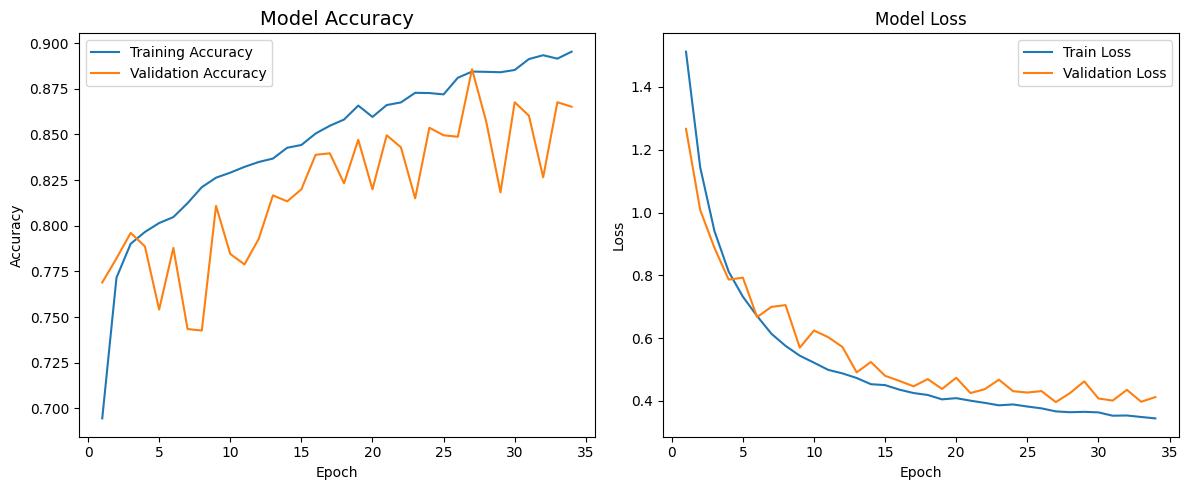

In [4]:
import matplotlib.pyplot as plt

# Extract data from history
train_accuracy = history.history.get('accuracy', [])
val_accuracy = history.history.get('val_accuracy', [])
train_loss = history.history.get('loss', [])
val_loss = history.history.get('val_loss', [])

epochs = range(1, len(train_accuracy) + 1)

# Plotting model accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plotting model loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Train Loss')  # Updated training color
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
# Set DPI to 300
plt.tight_layout()
plt.savefig('Hybrid_model.png', dpi=300)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.94      0.89       144
           1       0.95      0.84      0.89       165

    accuracy                           0.89       309
   macro avg       0.89      0.89      0.89       309
weighted avg       0.89      0.89      0.89       309



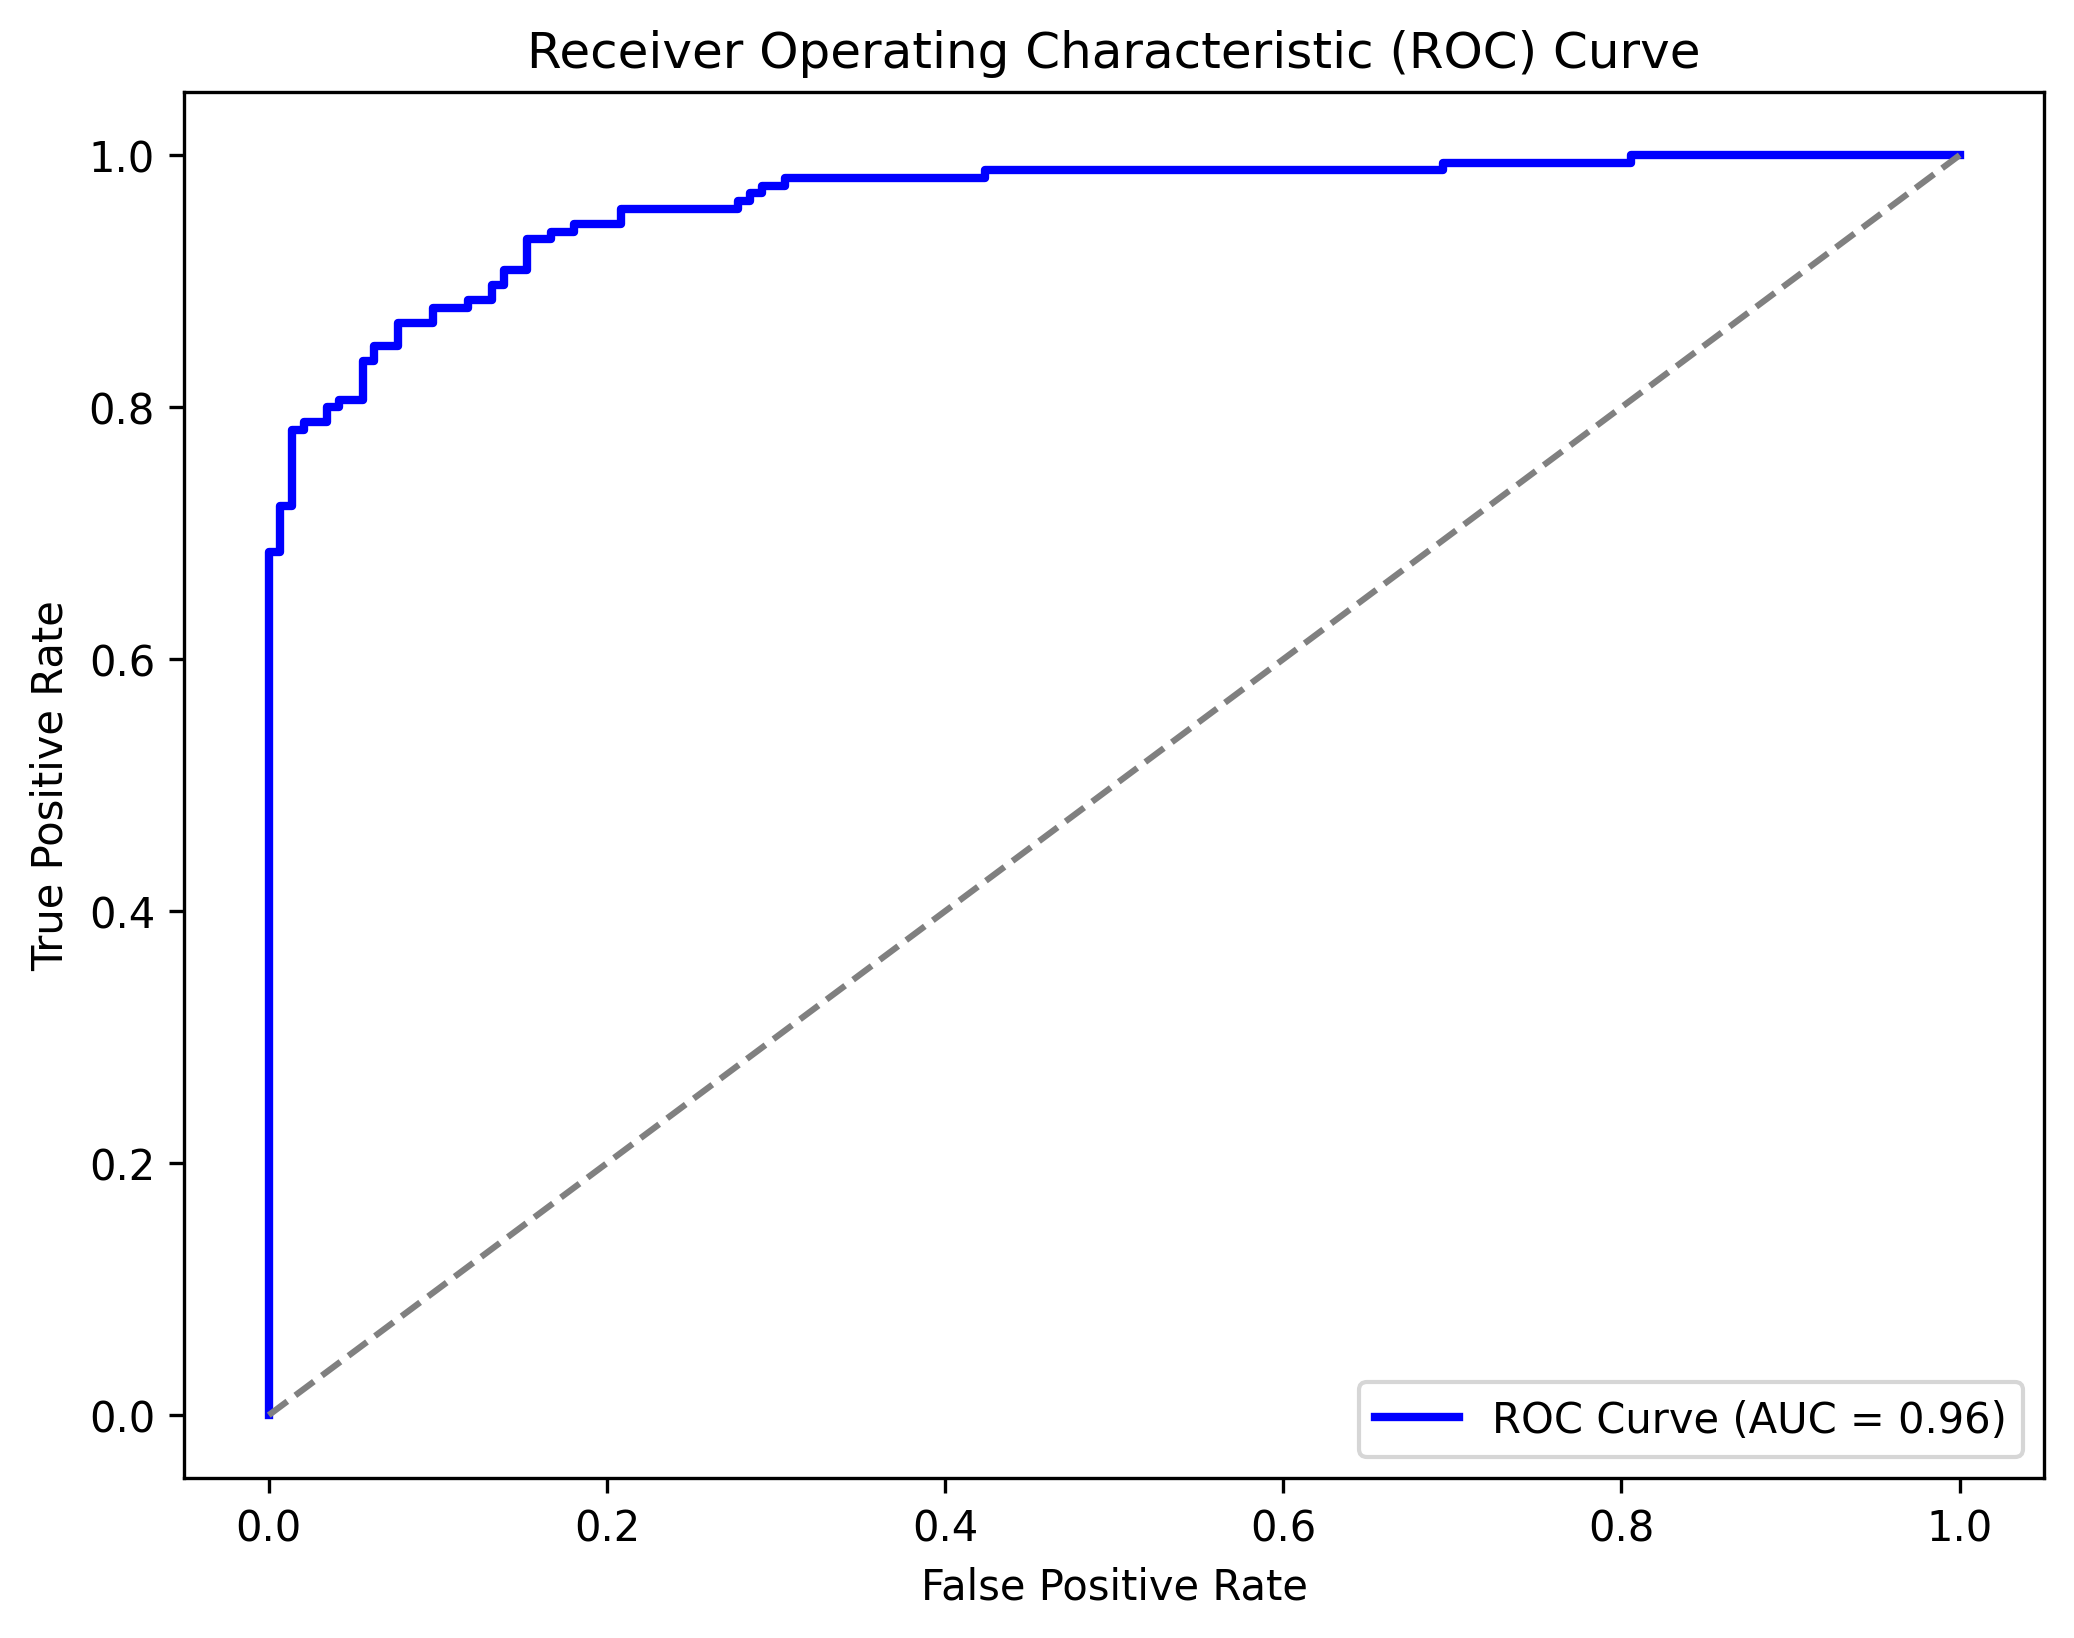

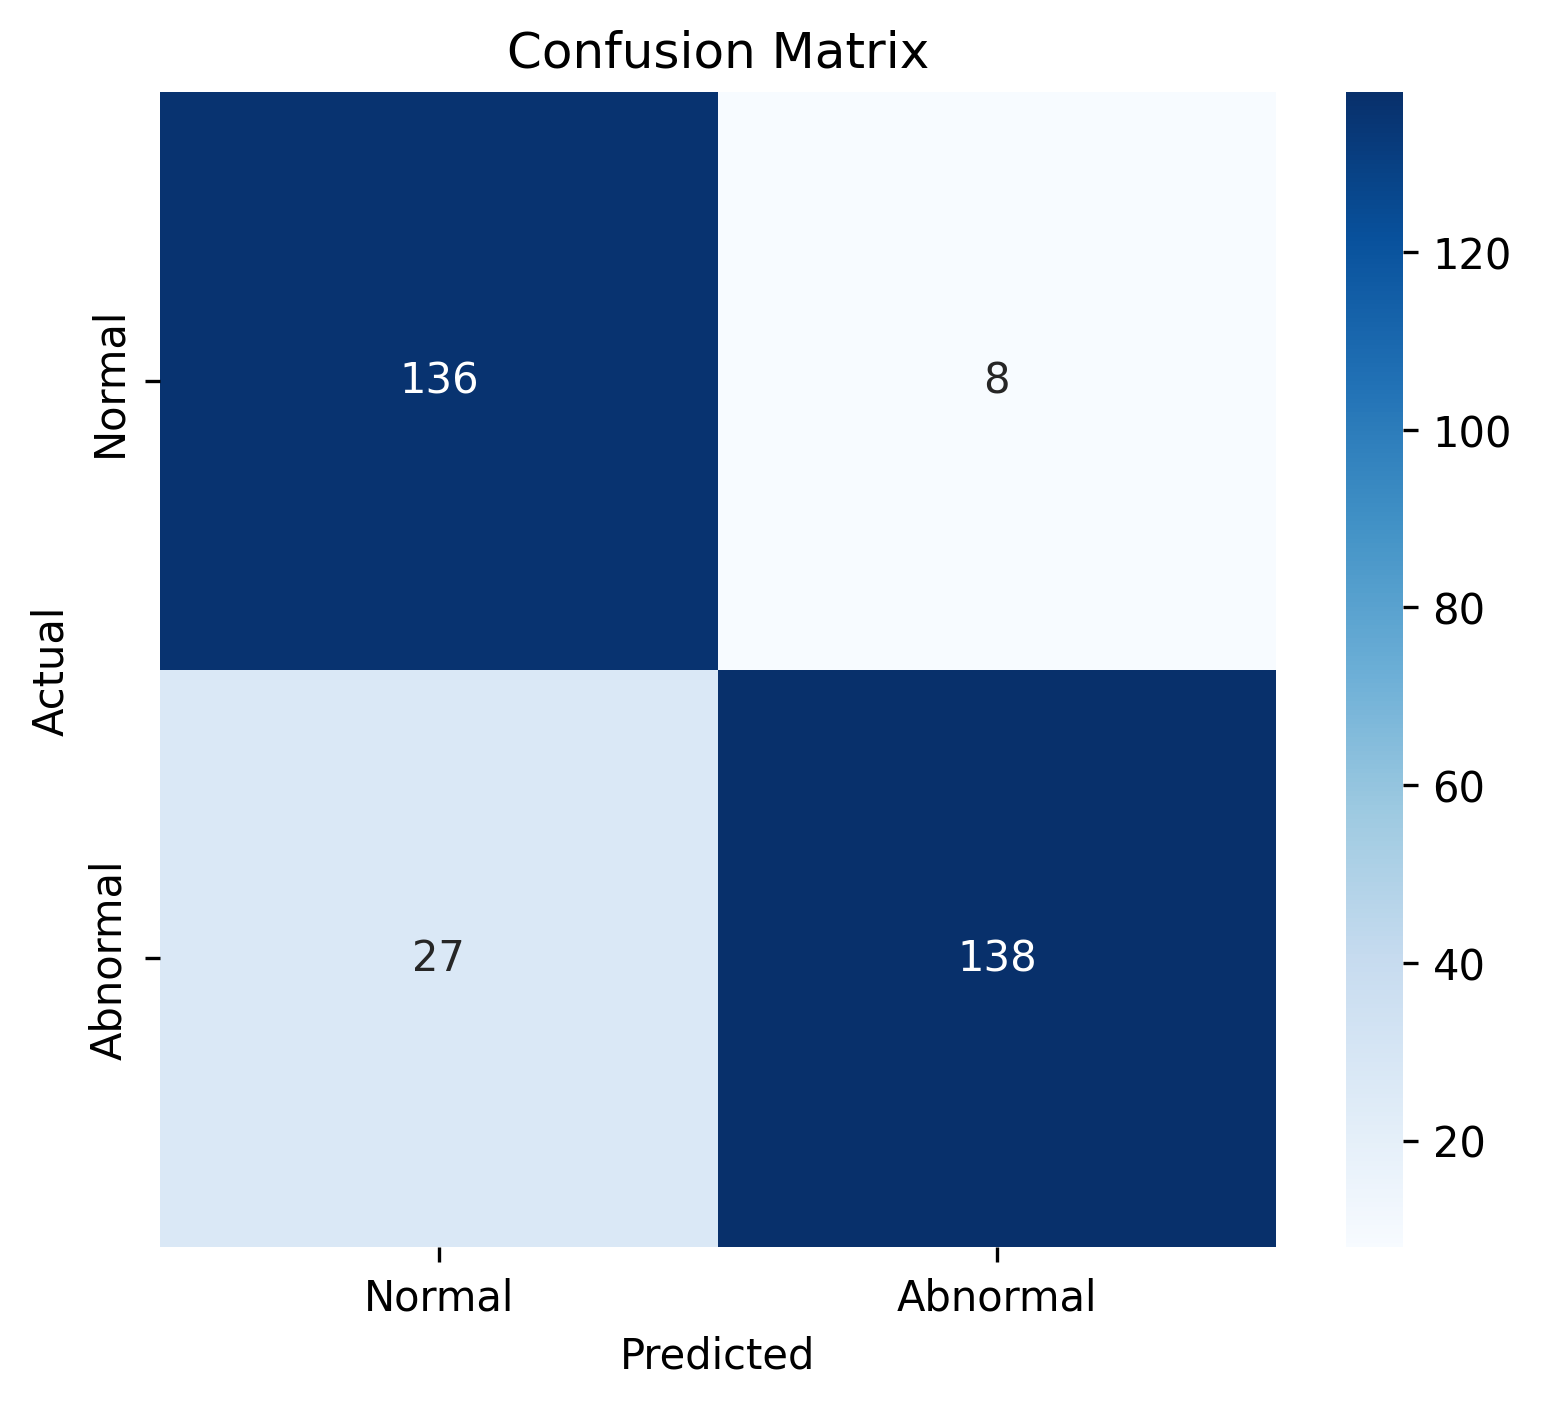

In [5]:
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_pred_probs = model.predict([x_test_ecg, x_test_pcg])  # Probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Convert to class labels
y_true = np.argmax(y_test_ecg, axis=1)  # True labels (assuming same for ECG & PCG)

# Compute ROC AUC Score
fpr, tpr, _ = roc_curve(y_true, y_pred_probs[:, 1])
roc_auc = auc(fpr, tpr)

# Generate Classification Report
class_report = classification_report(y_true, y_pred_classes)
print("Classification Report:\n", class_report)

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot ROC Curve
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig("roc_curve.png", dpi=300)  # Save at 300 dpi
plt.show()

# Plot Confusion Matrix
plt.figure(figsize=(6, 5), dpi=300)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300)  # Save at 300 dpi
plt.show()


In [6]:
# Calculate test accuracy for the hybrid model
from sklearn.metrics import accuracy_score

# Predict class labels for test set
pred_classes = np.argmax(model.predict([x_test_ecg, x_test_pcg]), axis=1)
true_classes = np.argmax(y_test_ecg, axis=1)

test_accuracy = accuracy_score(true_classes, pred_classes)
print(f"Test Accuracy: {test_accuracy:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
Test Accuracy: 0.8867


In [7]:
# Save the trained model to a file
model.save('/kaggle/working/Multimodal_Mamba_Hybrid_Model1.keras')
print("Model saved as 'Multimodal_Mamba_Hybrid_Model.keras'")


Model saved as 'Multimodal_Mamba_Hybrid_Model.keras'


Federated Round 1/5
  Test Loss: 1.3069 | Test Accuracy: 0.7605
Federated Round 2/5
  Test Loss: 0.9495 | Test Accuracy: 0.8252
Federated Round 3/5
  Test Loss: 0.7953 | Test Accuracy: 0.7961
Federated Round 4/5
  Test Loss: 0.5975 | Test Accuracy: 0.8479
Federated Round 5/5
  Test Loss: 0.5181 | Test Accuracy: 0.8479
Federated model saved as 'Multimodal_Mamba_Federated_Model.keras'


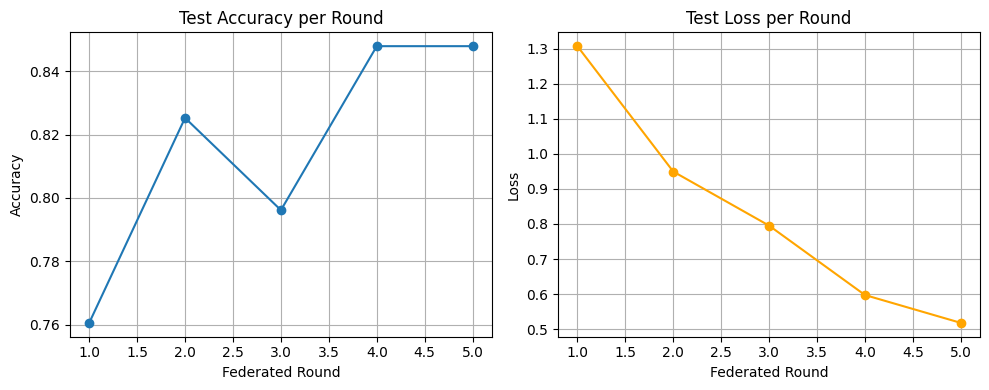

In [8]:
# --- Federated Learning with Evaluation and Visualization ---
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Partition data for federated simulation
def partition_data(x_ecg, x_pcg, y, num_clients=3):
    size = len(y) // num_clients
    partitions = []
    for i in range(num_clients):
        start = i * size
        end = (i + 1) * size if i < num_clients - 1 else len(y)
        partitions.append((x_ecg[start:end], x_pcg[start:end], y[start:end]))
    return partitions

num_clients = 3
client_partitions = partition_data(x_train_ecg, x_train_pcg, y_train_ecg, num_clients=num_clients)

def average_weights(weight_list):
    avg_weights = []
    for weights in zip(*weight_list):
        avg_weights.append(np.mean(weights, axis=0))
    return avg_weights

num_rounds = 5
local_epochs = 2
batch_size = 16

global_model = hybrid_transformer_model()
global_weights = global_model.get_weights()

# For logging
round_accuracies = []
round_losses = []

for rnd in range(num_rounds):
    print(f"Federated Round {rnd+1}/{num_rounds}")
    client_weights = []
    for cid in range(num_clients):
        model = hybrid_transformer_model()
        model.set_weights(global_weights)
        x_ecg, x_pcg, y = client_partitions[cid]
        model.fit([x_ecg, x_pcg], y, epochs=local_epochs, batch_size=batch_size, verbose=0)
        client_weights.append(model.get_weights())
    global_weights = average_weights(client_weights)
    global_model.set_weights(global_weights)
    # Evaluate on test set after each round
    loss, acc = global_model.evaluate([x_test_ecg, x_test_pcg], y_test_ecg, verbose=0)
    round_accuracies.append(acc)
    round_losses.append(loss)
    print(f"  Test Loss: {loss:.4f} | Test Accuracy: {acc:.4f}")

# Save the final global model
global_model.save('Multimodal_Mamba_Federated_Model.keras')
print("Federated model saved as 'Multimodal_Mamba_Federated_Model.keras'")

# Plot accuracy and loss curves
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(range(1, num_rounds+1), round_accuracies, marker='o')
plt.title('Test Accuracy per Round')
plt.xlabel('Federated Round')
plt.ylabel('Accuracy')
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(range(1, num_rounds+1), round_losses, marker='o', color='orange')
plt.title('Test Loss per Round')
plt.xlabel('Federated Round')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# --- Additional Evaluation Metrics for Federated Model ---
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

# Predict on test set
y_pred_probs = global_model.predict([x_test_ecg, x_test_pcg])
# If binary classification, threshold at 0.5
y_pred = (y_pred_probs > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test_ecg, y_pred))

# Multilabel confusion matrix: print for each class
if len(y_test_ecg.shape) > 1 and y_test_ecg.shape[1] > 1:
    for i in range(y_test_ecg.shape[1]):
        print(f"Confusion Matrix for class {i}:")
        print(confusion_matrix(y_test_ecg[:, i], y_pred[:, i]))
else:
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_ecg, y_pred))

# ROC-AUC (works for binary or multilabel)
try:
    auc = roc_auc_score(y_test_ecg, y_pred_probs)
    print(f"ROC-AUC Score: {auc:.4f}")
except Exception as e:
    print(f"ROC-AUC calculation error: {e}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.87      0.84       144
           1       0.88      0.82      0.85       165

   micro avg       0.85      0.84      0.84       309
   macro avg       0.85      0.84      0.84       309
weighted avg       0.85      0.84      0.84       309
 samples avg       0.84      0.84      0.84       309

Confusion Matrix for class 0:
[[136  29]
 [ 19 125]]
Confusion Matrix for class 1:
[[126  18]
 [ 30 135]]
ROC-AUC Score: 0.9180


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [15]:
for i, (x_ecg, x_pcg, y) in enumerate(client_partitions):
    print(f"Client {i}: {x_ecg.shape[0]} samples")

Client 0: 7285 samples
Client 1: 6596 samples
Client 2: 0 samples


In [ ]:
# --- Additional Evaluation Metrics for Federated Model ---
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

# Predict on test set
y_pred_probs = global_model.predict([x_test_ecg, x_test_pcg])
# If binary classification, threshold at 0.5
y_pred = (y_pred_probs > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test_ecg, y_pred))

# Multilabel confusion matrix: print for each class
if len(y_test_ecg.shape) > 1 and y_test_ecg.shape[1] > 1:
    for i in range(y_test_ecg.shape[1]):
        print(f"Confusion Matrix for class {i}:")
        print(confusion_matrix(y_test_ecg[:, i], y_pred[:, i]))
else:
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_ecg, y_pred))

# ROC-AUC (works for binary or multilabel)
try:
    auc = roc_auc_score(y_test_ecg, y_pred_probs)
    print(f"ROC-AUC Score: {auc:.4f}")
except Exception as e:
    print(f"ROC-AUC calculation error: {e}")